# This is a sample Jupyter Notebook

Below is an example of a code cell. 
Put your cursor into the cell and press Shift+Enter to execute it and select the next one, or click 'Run Cell' button.

Press Double Shift to search everywhere for classes, files, tool windows, actions, and settings.

To learn more about Jupyter Notebooks in PyCharm, see [help](https://www.jetbrains.com/help/pycharm/ipython-notebook-support.html).
For an overview of PyCharm, go to Help -> Learn IDE features or refer to [our documentation](https://www.jetbrains.com/help/pycharm/getting-started.html).

In [4]:
import matplotlib.pyplot as plt
import numpy as np
!pip install numpy torch torchvision


  Using cached torch-2.10.0-cp314-cp314-manylinux_2_28_x86_64.whl.metadata (31 kB)
  Using cached torchvision-0.25.0-cp314-cp314-manylinux_2_28_x86_64.whl.metadata (5.4 kB)
  Using cached filelock-3.24.3-py3-none-any.whl.metadata (2.0 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached fsspec-2026.2.0-py3-none-any.whl.metadata (10 kB)
  Using cached cuda_bindings-12.9.4-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (2.6 kB)
  Using cached nvidia_cuda_nvrtc_cu12-12.8.93-py3-none-manylinux2010_x86_64.manylinux_2_12_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cuda_runtime_cu12-12.8.90-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cuda_cupti_cu12-12.8.90-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (1.7 kB)
  Using cached nvidia_cudnn_cu12-9.10.2.21-py3-none-manylinux_2_27_x86_64.whl.metadata (1.8 k

In [2]:
from torchvision import datasets, transforms,models as torch_models
import torchvision
from torch.utils.data import DataLoader, random_split
import torch.optim as optim
import torch
import torch.nn as nn
import numpy as np
import os
import matplotlib.pyplot as plt
global device

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')


# Models


In [3]:
def alex_net_creator():

    transform = transforms.Compose([
        transforms.Resize((227, 227)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    def create_model():
            alexnet=torchvision.models.alexnet(weights=None)
            criterion = nn.CrossEntropyLoss()
            optimizer = optim.SGD(alexnet.parameters(), lr=0.005, momentum=0.9)
            return alexnet, criterion, optimizer
    print("Tto")
    return transform,'alexnet',create_model
model_info = alex_net_creator
model_info()[2]()

Tto


(AlexNet(
   (features): Sequential(
     (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
     (1): ReLU(inplace=True)
     (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
     (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
     (4): ReLU(inplace=True)
     (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
     (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (7): ReLU(inplace=True)
     (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (9): ReLU(inplace=True)
     (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (11): ReLU(inplace=True)
     (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
   )
   (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
   (classifier): Sequential(
     (0): Dropout(p=0.5, inplace=False)
     (1): Linear(in_features=9216, out_feature

# Datasets

In [4]:
seed=None

def get_train_loaders_from_ds(ds,splits=1,batch_size=64):
    splitted_data = random_split(ds,[len(ds)//splits] * splits,generator=torch.Generator().manual_seed(seed) if seed else None)
    return [DataLoader(data,batch_size=batch_size,shuffle=True) for data in splitted_data]



In [5]:
transform,model_name,model_creator= model_info()
ds=datasets.CIFAR10(root='./data', train=True, download=True, transform=transform)
data_set_name= 'cifar10'


Tto


/home/marcos/PycharmProjects/vector-gd-compression/.venv/lib64/python3.14/site-packages/torchvision/datasets/cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


# Entenamento individual

In [6]:
train_loader = get_train_loaders_from_ds(ds,splits=1,batch_size=64)
model,criterion,optimizer = model_creator()

num_epochs=10
total_elements=0
gradients_per_file=20
gradientes={}
g_actual=0

for epoch in range(num_epochs):
    print(f"Running epoch {epoch}")
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        total_elements+=len(labels)

        g_idx=g_actual % gradients_per_file
        if g_idx==gradients_per_file-1:
            print(f"Total ={total_elements} Loss:={loss}")
        for name, param in model.named_parameters():
            if param.grad is not None:
                if  name not in gradientes:
                    gradientes[name] = np.zeros((gradients_per_file,*param.data.shape))
                gradientes[name][g_idx]=param.grad.detach().cpu().numpy()
                if g_idx==gradients_per_file-1:
                    np.savez_compressed(f'./data/gradientes/{model_name}/{data_set_name}/gradients.{name}.{g_actual//gradients_per_file}.npz',gradientes[name])
        g_actual+=1
        optimizer.step()


Running epoch 0
Total =1280 Loss:=6.625070095062256
Total =2560 Loss:=6.3715500831604
Total =3840 Loss:=5.590795516967773
Total =5120 Loss:=5.409756660461426
Total =6400 Loss:=3.3543572425842285
Total =7680 Loss:=2.374021530151367
Total =8960 Loss:=2.3127315044403076
Total =10240 Loss:=2.3293190002441406
Total =11520 Loss:=2.3675715923309326
Total =12800 Loss:=2.3001019954681396
Total =14080 Loss:=2.395134925842285
Total =15360 Loss:=2.295515298843384
Total =16640 Loss:=2.2242939472198486
Total =17920 Loss:=2.1499295234680176
Total =19200 Loss:=2.122755527496338
Total =20480 Loss:=2.1712019443511963
Total =21760 Loss:=2.0113723278045654
Total =23040 Loss:=2.008910894393921
Total =24320 Loss:=2.0968101024627686
Total =25600 Loss:=1.9957247972488403
Total =26880 Loss:=1.849348545074463
Total =28160 Loss:=1.920630931854248
Total =29440 Loss:=2.0388922691345215
Total =30720 Loss:=1.9119778871536255
Total =32000 Loss:=1.7897906303405762
Total =33280 Loss:=1.848658800125122
Total =34560 Loss

KeyboardInterrupt: 

# Entrenamiento doble

In [9]:
import threading
splits=2
loaders = get_train_loaders_from_ds(ds,splits=splits,batch_size=64)

model,criterion,optimizer = model_creator()
models = [model_creator() for _ in loaders]
base_state_dict=models[0][0].state_dict()
for m in models:
    m[0].load_state_dict(base_state_dict)
num_epochs=12
total_elements=0
gradients_per_file=20
gradientes={}
g_actual=0
track_layers=['features.6.weight','features.6.bias','classifier.6.weight','classifier.6.bias','classifier.4.weight','classifier.4.bias']


for epoch in range(num_epochs):
    print(f"Running epoch {epoch}")
    for batches in zip(*loaders):
        model_idx=0
        g_idx=g_actual % gradients_per_file

        for (model,criterion,optimizer),(inputs,labels) in zip(models,batches):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            if g_idx==gradients_per_file-1:
                print(f"Model {model_idx}  Loss:={loss}")


            for name, param in model.named_parameters():
                    if param.grad is not None:
                        if track_layers and name not in track_layers:
                            #print(name,track_layers)
                            continue
                        if  name not in gradientes:
                            gradientes[name] = {}
                        if model_idx not in gradientes[name]:
                            gradientes[name][model_idx]=np.zeros((gradients_per_file,*param.data.shape))
                        gradientes[name][model_idx][g_idx]=param.grad.detach().cpu().numpy()
                        if g_idx==gradients_per_file-1:
                            dir_name=f"./data/gradientes/split/{model_name}/{data_set_name}/{model_idx}"
                            os.makedirs(dir_name,exist_ok=True)

                            t=threading.Thread(target= lambda : np.savez_compressed(f'{dir_name}/gradients.{name}.{g_actual//gradients_per_file}.npz',gradientes[name][model_idx]))
                            t.start()

            model_idx+=1

        with torch.no_grad():
            for params in zip(*[m.parameters() for (m,_,_) in models]):
                avg_gradient=None
                if params[0].grad is None:
                    break

                for param in params:
                    if avg_gradient is  None:
                        avg_gradient=param.grad/splits
                    else:
                        avg_gradient+=param.grad/splits

                for param in params:
                    param.grad.copy_(avg_gradient)

        for (model,criterion,optimizer),(inputs,labels) in zip(models,batches):
            optimizer.step()

        g_actual+=1



Running epoch 0
Model 0  Loss:=6.821652412414551
Model 1  Loss:=6.823174953460693
Model 0  Loss:=3.6535041332244873
Model 1  Loss:=3.6232750415802
Model 0  Loss:=6.009562015533447
Model 1  Loss:=6.223658084869385
Model 0  Loss:=5.559202194213867
Model 1  Loss:=5.411057472229004
Model 0  Loss:=3.6379358768463135
Model 1  Loss:=2.8888299465179443
Model 0  Loss:=2.327162742614746
Model 1  Loss:=2.367465019226074
Model 0  Loss:=2.2550487518310547
Model 1  Loss:=2.340254306793213
Model 0  Loss:=2.290790319442749
Model 1  Loss:=2.2532896995544434
Model 0  Loss:=2.0970194339752197
Model 1  Loss:=2.1008639335632324
Model 0  Loss:=2.0256600379943848
Model 1  Loss:=1.9838398694992065
Model 0  Loss:=2.1178808212280273
Model 1  Loss:=1.9097791910171509
Model 0  Loss:=1.8513307571411133
Model 1  Loss:=1.9936130046844482
Model 0  Loss:=1.7391051054000854
Model 1  Loss:=1.8942426443099976
Model 0  Loss:=2.0070667266845703
Model 1  Loss:=2.1041159629821777
Model 0  Loss:=1.7757236957550049
Model 1  Lo

# Prueba distribucion

Running epoch 0
Lala 1////99//
Total =1280 Loss:=6.914262294769287
Total =2560 Loss:=6.914147853851318
Total =3840 Loss:=6.9148688316345215
Total =5120 Loss:=6.913254737854004
Total =6400 Loss:=6.914175033569336
Lala -99////0//
Not waiting anymore


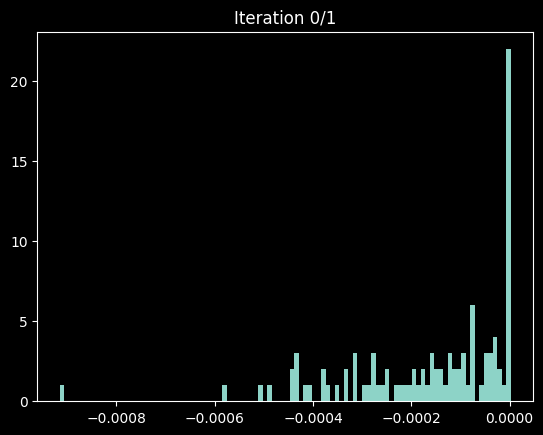

Total =7680 Loss:=6.914417743682861
Total =8960 Loss:=6.913331508636475
Total =10240 Loss:=6.912725925445557
Total =11520 Loss:=6.913260459899902
Total =12800 Loss:=6.9110283851623535
Lala -199////0//
Not waiting anymore


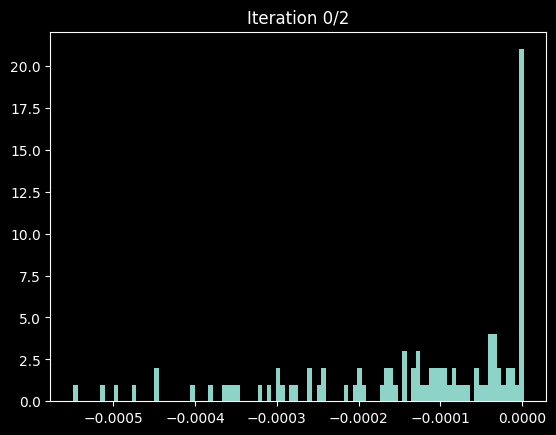

Total =14080 Loss:=6.91115140914917
Total =15360 Loss:=6.910103797912598
Total =16640 Loss:=6.9098687171936035
Total =17920 Loss:=6.909858226776123
Total =19200 Loss:=6.908634662628174
Lala -299////0//
Not waiting anymore


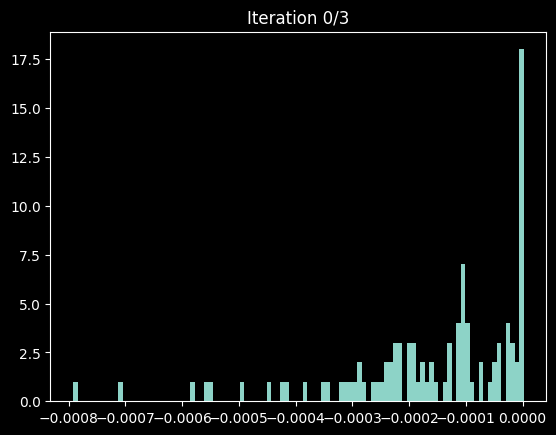

Total =20480 Loss:=6.908352375030518
Total =21760 Loss:=6.90921688079834
Total =23040 Loss:=6.907059669494629
Total =24320 Loss:=6.908542156219482
Total =25600 Loss:=6.909616470336914
Lala -399////0//
Not waiting anymore


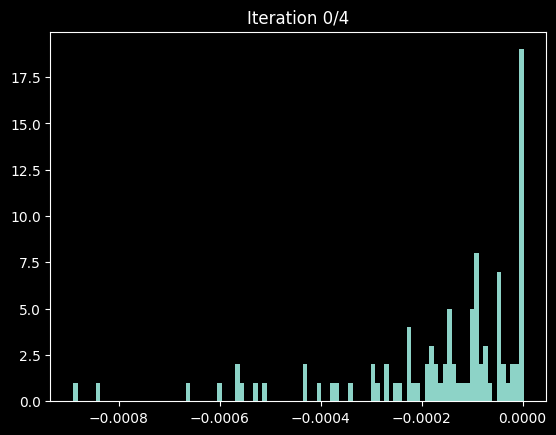

Total =26880 Loss:=6.905034065246582
Total =28160 Loss:=6.905436038970947
Total =29440 Loss:=6.906845569610596
Total =30720 Loss:=6.904366493225098
Total =32000 Loss:=6.903995037078857
Lala -499////0//
Not waiting anymore


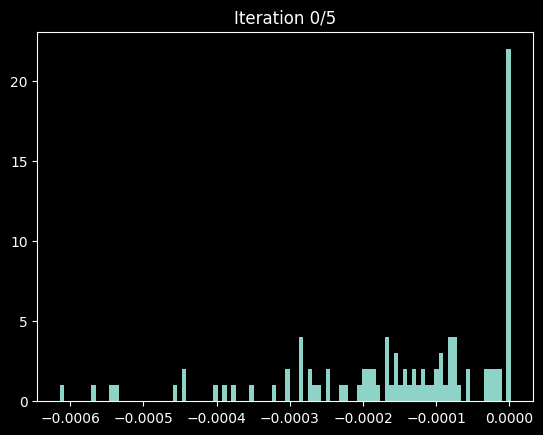

Total =33280 Loss:=6.8991594314575195
Total =34560 Loss:=6.900363922119141
Total =35840 Loss:=6.901553153991699
Total =37120 Loss:=6.901838779449463
Total =38400 Loss:=6.901238918304443
Lala -599////0//
Not waiting anymore


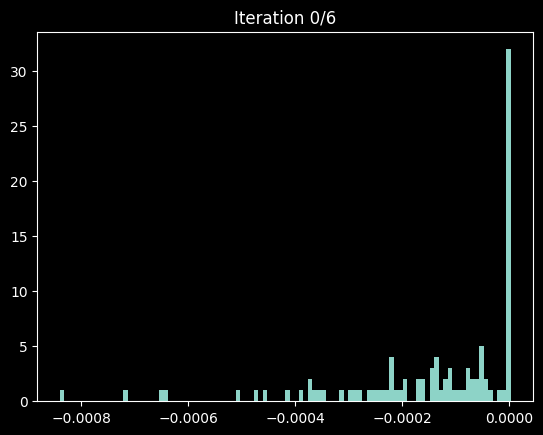

Total =39680 Loss:=6.898322582244873
Total =40960 Loss:=6.89765739440918
Total =42240 Loss:=6.897629737854004
Total =43520 Loss:=6.896003723144531
Total =44800 Loss:=6.895582675933838
Lala -699////0//
Not waiting anymore


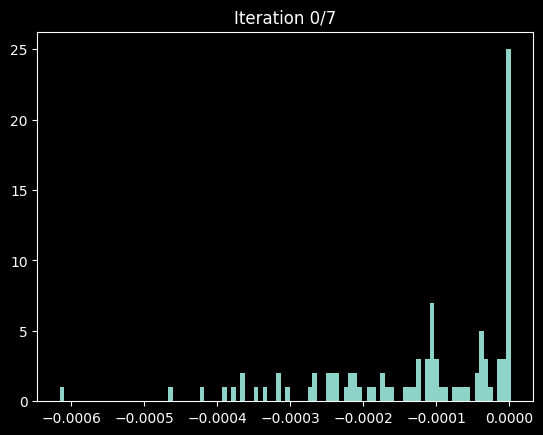

Total =46080 Loss:=6.8916850090026855
Total =47360 Loss:=6.890782833099365
Total =48640 Loss:=6.892800807952881
Total =49920 Loss:=6.893664360046387
Running epoch 1
Total =51152 Loss:=6.891312599182129
Lala -799////0//
Not waiting anymore


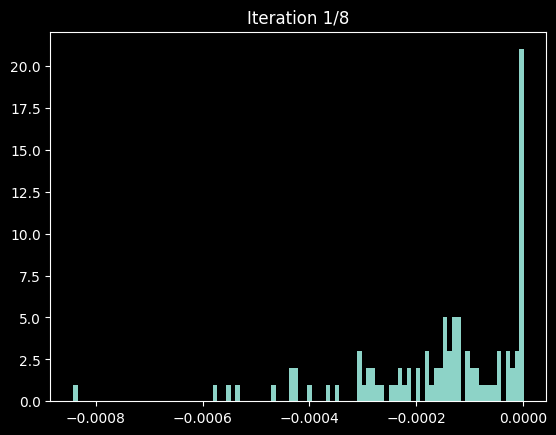

Total =52432 Loss:=6.888607025146484
Total =53712 Loss:=6.8885321617126465
Total =54992 Loss:=6.888033390045166
Total =56272 Loss:=6.8861212730407715
Total =57552 Loss:=6.885515213012695
Lala -899////0//
Not waiting anymore


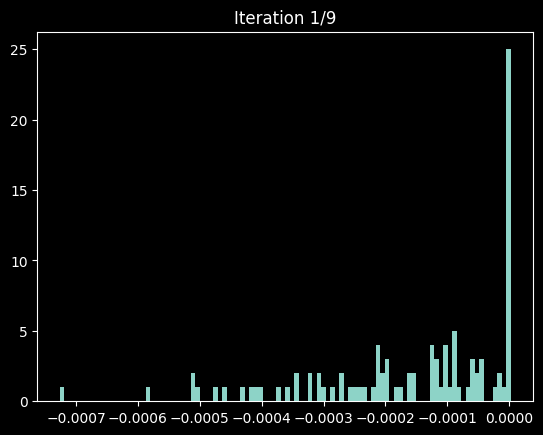

Total =58832 Loss:=6.88237190246582
Total =60112 Loss:=6.882728576660156
Total =61392 Loss:=6.882155895233154
Total =62672 Loss:=6.882955551147461
Total =63952 Loss:=6.883647441864014
Lala -999////0//
Not waiting anymore


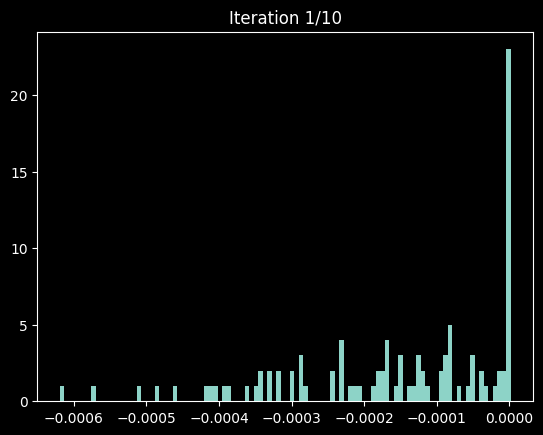

Total =65232 Loss:=6.876072883605957
Total =66512 Loss:=6.87697172164917
Total =67792 Loss:=6.876711368560791
Total =69072 Loss:=6.876882076263428


In [ ]:
train_loader = get_train_loaders_from_ds(ds,splits=1,batch_size=64)[0]
model,criterion,optimizer = model_creator()

num_epochs=10
total_elements=0
gradients_per_file=20
gradientes={}
g_actual=0
wait_for=2
compute_gradients_for=100
remaining_gradients=compute_gradients_for
track_layer='classifier.6.weight'
inidces = []
gradientes_de_batches= None
current_batch_idx=0
for epoch in range(num_epochs):
    print(f"Running epoch {epoch}")
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        total_elements+=len(labels)

        g_idx=g_actual % gradients_per_file
        if g_idx==gradients_per_file-1:
            print(f"Total ={total_elements} Loss:={loss}")
        for name, param in model.named_parameters():
            if  name != track_layer:
                continue
            if param.grad is not None:
                gradiente_actual=param.grad.detach().cpu().numpy().reshape(-1)
                if  gradientes_de_batches is None:
                    gradientes_de_batches= np.zeros((compute_gradients_for,*gradiente_actual.shape))
                gradientes_de_batches[remaining_gradients-1,:]=gradiente_actual

        g_actual+=1
        remaining_gradients-=1
        wait_for-=1
        if wait_for>0 or remaining_gradients==0:
            print(f"Lala {wait_for}////{remaining_gradients}//")
            optimizer.step()
            if wait_for<0:
                print("Not waiting anymore")
                current_batch_idx+=1
                plt.title(f"Iteration {epoch}/{current_batch_idx}")
                plt.hist(gradientes_de_batches[:,0],bins=100)
                plt.show()
            remaining_gradients=compute_gradients_for


